# Independent reproduction — Keskar et al. (2017), Figure 3: **F1, C1 and C2**

## Full experiment • Kaggle **2 × Tesla T4 GPUs** • PyTorch

This is the **full-run** Kaggle version. There are no reduced-data profiles or fabricated figures. **Run All** trains six real models (F1, C1, C2 × small and large batches), computes their full-dataset interpolation curves, and writes checkpoints, logs, CSV/JSON results and PNG/PDF/SVG plots under `/kaggle/working/Keskar_Figure3_Independent/`.

**Dual-GPU design:** Kaggle exposes two ~16 GB Tesla T4 devices. This notebook launches two **separate subprocesses** and binds each to a different GPU via `CUDA_VISIBLE_DEVICES=0` or `1`. A GPU trains **one entire model**, not half a distributed model. This avoids cross-device BN synchronization and makes independent SB/LB training straightforward. As a GPU becomes free, it receives the next experiment. Interpolation jobs are also assigned across both GPUs.

**Source and restriction:** Keskar et al. (2017), *On Large-Batch Training for Deep Learning: Generalization Gap and Sharp Minima*, [original paper](https://arxiv.org/pdf/1609.04836). Section 2.2, Figure 3, Appendices A/B. This independent PyTorch implementation does **not** consult existing implementations of the paper.

| Experiment | Architecture | Dataset | SB | LB |
|---|---|---|---:|---:|
| F1 | MLP, five 512-wide BN/ReLU hidden layers | MNIST | 256 | 6,000 |
| C1 | Two convolutional layers plus 384/192 dense layers | CIFAR-10 | 256 | 5,000 |
| C2 | Thirteen VGG-style conv layers, 512 dense hidden | CIFAR-10 | 256 | 5,000 |

**Unspecified choices / deviations:** Adam learning rate `1e-3`, constant LR and no weight decay; `uint8 / 255` without additional normalization or augmentation; shared initialization for SB/LB; BN-before-ReLU; convolution padding/pooling details as in the model source below; dropout probability 0.5 in the C1/C2 dense classifier; convergence stopping based on plateauing training-set loss plus an epoch cap. The large effective batch is computed by gradient accumulation, but BN statistics during training are computed on **physical microbatches**, not across the entire effective batch. These are material departures from what the original does not explicitly specify. BN statistics are re-estimated from training data **independently for each interpolation α**; test data never recalibrate BN.

The original reports five trials for mean test accuracies; this notebook produces **one matched SB/LB pair for each panel**. To reproduce five-trial statistics, repeat with five seeds in separate output folders. No reference-code lookup is performed.

## 1. Kaggle setup

Select **Settings → Accelerator → GPU T4 x2** and **enable Internet** for the first dataset download. The code asserts that *exactly two* CUDA devices are visible, so it cannot silently run on one GPU. Both datasets are downloaded using official torchvision dataset loaders before parallel workers start, to avoid races. For an offline Kaggle session, attach/download MNIST and CIFAR-10 ahead of time in their expected torchvision directories and set `DATA_ROOT` accordingly.

**Persistence:** Kaggle's `/kaggle/working` is writable during this session. Save a Kaggle **Version** to preserve `/kaggle/working` outputs. To resume in a new session, attach the saved output as a Kaggle dataset and set `PREVIOUS_RUN` to the directory containing the prior checkpoint files before running all cells. Simply restarting a session without restoring previous outputs does *not* preserve checkpoints.

The full experiment runs until the preset epoch caps or plateau stopping. It is computationally heavy (especially C2). No shortened training mode is included.

In [1]:
from __future__ import annotations
import os,sys,json,shutil,subprocess,time,threading,platform
from pathlib import Path
from datetime import datetime,timezone
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision.datasets import MNIST,CIFAR10

ROOT=Path('/kaggle/working/Keskar_Figure3_Independent')
DATA_ROOT=Path('/kaggle/working/keskar_data')
# OPTIONAL: prior Kaggle output attached as input, e.g.:
# PREVIOUS_RUN=Path('/kaggle/input/keskar-prior/Keskar_Figure3_Independent')
PREVIOUS_RUN=None

RUN_PANELS=['F1','C1','C2']    # All three final figures; nothing is skipped.
SEED=2026
PROFILE='full'
SHARE_INITIALIZATION=True
USE_AMP=True
TRAINING_LR=1e-3
WEIGHT_DECAY=0.0

# Original effective batch sizes are preserved.
BATCH_SIZES={
    'F1':{'SB':256,'LB':6000},
    'C1':{'SB':256,'LB':5000},
    'C2':{'SB':256,'LB':5000}
}
# Each worker uses exactly one T4. Smaller physical batches use gradient accumulation.
# Physical BN microbatches are disclosed deviations from original full-batch BN.
MICROBATCH={
    'F1':{'SB':256,'LB':1024},
    'C1':{'SB':256,'LB':128},
    'C2':{'SB':128,'LB':64}
}
CFG={
    'epochs':{'F1':150,'C1':150,'C2':120},
    'train_limit':None,
    'bn_n':None,'eval_train_n':None,'eval_test_n':None,
    'points_per_segment':11,
    'eval_every':{'F1':1,'C1':5,'C2':5},
    'patience':10
}

assert torch.cuda.is_available(), 'Kaggle GPU accelerator is not enabled.'
assert torch.cuda.device_count()==2, (
    f'Expected 2 Tesla T4s, found {torch.cuda.device_count()} GPUs. '
    'Set Kaggle Settings → Accelerator → GPU T4 x2.'
)
for i in range(2): print(f'GPU {i}: {torch.cuda.get_device_name(i)}')
ROOT.mkdir(parents=True,exist_ok=True)
DATA_ROOT.mkdir(parents=True,exist_ok=True)
if PREVIOUS_RUN is not None:
    prior=Path(PREVIOUS_RUN)
    assert prior.is_dir(),f'Prior Kaggle output not found: {prior}'
    for folder in ('checkpoints','landscapes','figures'):
        if (prior/folder).exists():
            shutil.copytree(prior/folder,ROOT/folder,dirs_exist_ok=True)
    print('Restored previous saved artifacts from',prior)

RUN_CONFIG={
 'seed':SEED,'share_initialization':SHARE_INITIALIZATION,'use_amp':USE_AMP,
 'lr':TRAINING_LR,'weight_decay':WEIGHT_DECAY,'cfg':CFG,
 'effective_batches':BATCH_SIZES,'microbatches':MICROBATCH,
 'original_implementation_consulted':False,
 'device_assignment':'one independent worker per physical T4',
 'preprocessing':'uint8 pixel / 255; no channel normalization or augmentation',
 'BN_interpolation':'reset and recalculate training-set statistics at every alpha',
 'version':'kaggle_2t4_independent_full_v1'
}
config_path=ROOT/'run_config.json'
if config_path.exists():
    old_config=json.loads(config_path.read_text())
    if old_config!=RUN_CONFIG:
        raise ValueError('Existing run_config.json differs from current run. '
                         'Use a clean ROOT or restore matching settings.')
config_path.write_text(json.dumps(RUN_CONFIG,indent=2))
print('All files will save under:',ROOT)
print('Full-dataset training and evaluation configured.')

GPU 0: Tesla T4
GPU 1: Tesla T4
All files will save under: /kaggle/working/Keskar_Figure3_Independent
Full-dataset training and evaluation configured.


## 2. Download MNIST and CIFAR-10 once

This step downloads only the official datasets. **Internet must be enabled the first time.** Workers do not race to extract the same files. Raw labels stay unchanged.

In [2]:
MNIST(str(DATA_ROOT),train=True,download=True)
MNIST(str(DATA_ROOT),train=False,download=True)
CIFAR10(str(DATA_ROOT),train=True,download=True)
CIFAR10(str(DATA_ROOT),train=False,download=True)
print('Datasets cached:',DATA_ROOT)

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 480kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.84MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 15.8MB/s]
100%|██████████| 170M/170M [13:40<00:00, 208kB/s]


Datasets cached: /kaggle/working/keskar_data


## 3. Actual model architectures, training, checkpoint-resume and interpolation implementation

The next cell writes a self-contained Python worker to `/kaggle/working/keskar_worker.py`. Its **source is part of this notebook**, and it includes all architectures, loaders, actual optimizer steps, batch-norm recalibration, accuracy/loss evaluations and caching. Using two independent Python processes (rather than `torch.nn.DataParallel`) gives each job a dedicated GPU and isolated GPU memory. The worker treats `run_config.json` as immutable; a changed run configuration refuses to reuse a conflicting checkpoint.

In [3]:
WORKER_PATH=Path('/kaggle/working/keskar_worker.py')
WORKER_SOURCE = r"""
from __future__ import annotations
import os,sys,random,json,math,time,csv,copy,hashlib,platform
from pathlib import Path
from contextlib import nullcontext
from datetime import datetime,timezone
import numpy as np
import matplotlib
matplotlib.use('Agg')
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset,Subset,DataLoader
from torchvision.datasets import MNIST,CIFAR10

ROOT=Path(os.environ.get('KESKAR_ROOT','/kaggle/working/Keskar_Figure3_Independent'))
DATA_ROOT=Path(os.environ.get('KESKAR_DATA','/kaggle/working/keskar_data'))
ROOT.mkdir(parents=True,exist_ok=True)
DATA_ROOT.mkdir(parents=True,exist_ok=True)
CONFIG=json.loads((ROOT/'run_config.json').read_text())
SEED=CONFIG['seed']; PROFILE='full'; CFG=CONFIG['cfg']
SHARE_INITIALIZATION=CONFIG['share_initialization']; USE_AMP=CONFIG['use_amp']
SAVE_EVERY_EPOCH=True; TRAINING_LR=CONFIG['lr']; WEIGHT_DECAY=CONFIG['weight_decay']
BN_EPS=1e-5; BN_MOMENTUM=0.1
BATCH_SIZES=CONFIG['effective_batches'];MICROBATCH=CONFIG['microbatches']
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type!='cuda':raise RuntimeError('GPU worker requires CUDA; check Kaggle dual T4 setting')
# Worker only sees one physical GPU through CUDA_VISIBLE_DEVICES.
if torch.cuda.device_count()!=1:raise RuntimeError('Worker must see exactly ONE isolated GPU')
torch.set_num_threads(2)
torch.backends.cudnn.benchmark=True
torch.backends.cuda.matmul.allow_tf32=False

def panel_config_value(name,panel):
    value=CFG[name]
    return value.get(panel) if isinstance(value,dict) else value

def panel_seed(panel):
    return SEED+{'F1':0,'C1':1000,'C2':2000}[panel]


def utc_now():
    return datetime.now(timezone.utc).isoformat()

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def log_event(event, **fields):
    row = {'at_utc':utc_now(), 'event':event, 'profile':PROFILE, **fields}
    with open(ROOT/'EVENTS.jsonl', 'a', encoding='utf-8') as f:
        f.write(json.dumps(row, default=str) + '\n')

def atomic_torch_save(payload, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.part')
    torch.save(payload, tmp)
    os.replace(tmp, path)

def atomic_json_save(payload, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.part')
    tmp.write_text(json.dumps(payload, indent=2, allow_nan=False, default=str))
    os.replace(tmp, path)

def rng_get():
    return {
      'python':random.getstate(), 'numpy':np.random.get_state(),
      'torch':torch.get_rng_state(),
      'cuda':torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
    }

def rng_set(state):
    random.setstate(state['python']); np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'])
    if state['cuda'] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state['cuda'])

def panel_config_value(name, panel):
    value = CFG[name]
    return value.get(panel) if isinstance(value, dict) else value

def panel_seed(panel):
    return SEED + {'F1':0,'C1':1000,'C2':2000}[panel]



class F1Network(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [nn.Flatten()]
        in_dim = 784
        for _ in range(5):
            layers.extend([nn.Linear(in_dim,512), nn.BatchNorm1d(512,eps=BN_EPS,momentum=BN_MOMENTUM), nn.ReLU(inplace=False)])
            in_dim = 512
        layers.append(nn.Linear(512,10))
        self.net = nn.Sequential(*layers)
    def forward(self,x): return self.net(x)

class C1Network(nn.Module):
    def __init__(self):
        super().__init__()
        blocks=[]; in_channels=3
        for _ in range(2):
            blocks.extend([
                nn.Conv2d(in_channels,64,kernel_size=5,stride=2,padding=2),
                nn.BatchNorm2d(64,eps=BN_EPS,momentum=BN_MOMENTUM),
                nn.ReLU(inplace=False),
                nn.MaxPool2d(kernel_size=3,stride=2)
            ])
            in_channels=64
        self.features = nn.Sequential(*blocks)
        # 32->16->7->4->1 with the explicitly chosen padding/pool strides.
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64,384), nn.BatchNorm1d(384), nn.ReLU(), nn.Dropout(p=0.5),
            nn.Linear(384,192), nn.BatchNorm1d(192), nn.ReLU(), nn.Dropout(p=0.5),
            nn.Linear(192,10)
        )
    def forward(self,x): return self.classifier(self.features(x))

class C2Network(nn.Module):
    def __init__(self):
        super().__init__()
        blocks=[]; in_channels=3
        for width,repetitions in [(64,2),(128,2),(256,3),(512,3),(512,3)]:
            for _ in range(repetitions):
                blocks.extend([
                    nn.Conv2d(in_channels,width,kernel_size=3,stride=1,padding=1),
                    nn.BatchNorm2d(width,eps=BN_EPS,momentum=BN_MOMENTUM),
                    nn.ReLU(inplace=False)
                ])
                in_channels=width
            blocks.append(nn.MaxPool2d(kernel_size=2,stride=2))
        self.features = nn.Sequential(*blocks)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(512,512), nn.BatchNorm1d(512),
            nn.ReLU(), nn.Dropout(p=0.5), nn.Linear(512,10)
        )
    def forward(self,x): return self.classifier(self.features(x))

def make_model(panel):
    return {'F1':F1Network,'C1':C1Network,'C2':C2Network}[panel]()

PAPER_TARGETS = {
 'F1':{'train_SB':99.66,'train_LB':99.92,'test_SB':98.03,'test_LB':97.81},
 'C1':{'train_SB':99.89,'train_LB':99.66,'test_SB':80.04,'test_LB':77.26},
 'C2':{'train_SB':99.99,'train_LB':99.99,'test_SB':89.24,'test_LB':87.26},
}


_DATA_CACHE={}

def dataset_tensors(panel):
    key = 'MNIST' if panel=='F1' else 'CIFAR10'
    if key not in _DATA_CACHE:
        if key=='MNIST':
            train=MNIST(root=str(DATA_ROOT),train=True,download=True)
            test=MNIST(root=str(DATA_ROOT),train=False,download=True)
            xtr=train.data.unsqueeze(1).contiguous()
            ytr=train.targets.long()
            xte=test.data.unsqueeze(1).contiguous()
            yte=test.targets.long()
        else:
            train=CIFAR10(root=str(DATA_ROOT),train=True,download=True)
            test=CIFAR10(root=str(DATA_ROOT),train=False,download=True)
            xtr=torch.from_numpy(np.asarray(train.data).copy()).permute(0,3,1,2).contiguous()
            ytr=torch.tensor(train.targets,dtype=torch.long)
            xte=torch.from_numpy(np.asarray(test.data).copy()).permute(0,3,1,2).contiguous()
            yte=torch.tensor(test.targets,dtype=torch.long)
        assert xtr.dtype==torch.uint8 and xte.dtype==torch.uint8
        assert len(ytr)==(60000 if key=='MNIST' else 50000) and len(yte)==10000
        _DATA_CACHE[key]=(TensorDataset(xtr,ytr),TensorDataset(xte,yte))
    return _DATA_CACHE[key]

def fixed_subset(ds, n, seed):
    if n is None or int(n)>=len(ds): return ds
    rng=np.random.default_rng(seed)
    indices=rng.choice(len(ds),size=int(n),replace=False).tolist()
    return Subset(ds,indices)

def loader(ds, batch_size, shuffle=False, seed=0):
    gen = torch.Generator().manual_seed(int(seed))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=gen,
                      num_workers=0, pin_memory=(DEVICE.type=='cuda'), drop_last=False)

def to_device(raw_x, y):
    return raw_x.to(DEVICE,non_blocking=True).float().div_(255.0), y.to(DEVICE,non_blocking=True)



@torch.inference_mode()
def evaluate(model, ds, batch_size=256):
    model.eval(); total=0; ce_total=0.0; correct=0
    for raw_x,y in loader(ds,batch_size,shuffle=False):
        x,y=to_device(raw_x,y)
        logits=model(x)  # full fp32 evaluation
        ce=F.cross_entropy(logits,y,reduction='sum')
        if not torch.isfinite(ce):
            raise FloatingPointError('Nonfinite cross entropy in evaluation')
        ce_total+=float(ce.item())
        correct+=int((logits.argmax(dim=1)==y).sum().item())
        total+=len(y)
    assert total>0
    return {'loss':ce_total/total, 'acc':100.0*correct/total, 'n':total}

def run_identity(panel,regime):
    return {'panel':panel,'regime':regime,'profile':PROFILE,'seed':SEED,'shared_init':SHARE_INITIALIZATION,
            'effective_batch':BATCH_SIZES[panel][regime],
            'microbatch':MICROBATCH[panel][regime],
            'learning_rate':TRAINING_LR,'weight_decay':WEIGHT_DECAY,
            'pixel_scale':'divide_255','augmented':False,'amp':USE_AMP,
            'train_limit':CFG['train_limit'],
            'selection_train_n':panel_config_value('eval_train_n',panel),
            'selection_test_n':panel_config_value('eval_test_n',panel),
            'eval_every':panel_config_value('eval_every',panel),
            'patience':CFG['patience'], 'architecture_revision':'v1'}

def run_dir(panel,regime):
    init_tag='shared' if SHARE_INITIALIZATION else 'independent'
    sample_tag='complete_data'
    return ROOT/'checkpoints'/f'{panel}_{regime}_{PROFILE}_seed{SEED}_{init_tag}_{sample_tag}'

def run_seed(panel,regime):
    return panel_seed(panel)+(0 if regime=='SB' else 100000)

def make_amp_scaler():
    if hasattr(torch,'amp') and hasattr(torch.amp,'GradScaler'):
        return torch.amp.GradScaler('cuda',enabled=USE_AMP and DEVICE.type=='cuda')
    return torch.cuda.amp.GradScaler(enabled=USE_AMP and DEVICE.type=='cuda')

def train_epoch(model,optimizer,scaler,ds,panel,regime,epoch):
    model.train()
    batch=BATCH_SIZES[panel][regime]
    micro=MICROBATCH[panel][regime]
    # Consistent per-epoch permutation; optimization batches differ by regime.
    dl=loader(ds,micro,shuffle=True,seed=panel_seed(panel)+epoch*53)
    total=0; correct=0; loss_total=0.0; updates=0
    optimizer.zero_grad(set_to_none=True)
    group_n=0; group_target=min(batch,len(ds))
    for raw_x,y in dl:
        # DataLoader yields uniform microchunks. A large virtual batch can cross a
        # microbatch boundary, so split the tensor if necessary.
        start=0
        while start<len(y):
            take=min(len(y)-start,group_target-group_n)
            xx,yy=to_device(raw_x[start:start+take],y[start:start+take])
            amp_ctx=(torch.autocast(device_type='cuda',dtype=torch.float16)
                     if USE_AMP and DEVICE.type=='cuda' else nullcontext())
            with amp_ctx:
                logits=model(xx)
                ce_sum=F.cross_entropy(logits,yy,reduction='sum')
                loss=ce_sum/group_target
            if not torch.isfinite(ce_sum):
                raise FloatingPointError(f'Nonfinite train CE at {panel}/{regime} epoch {epoch}')
            scaler.scale(loss).backward()
            loss_total+=float(ce_sum.detach().item())
            correct+=int((logits.detach().argmax(1)==yy).sum().item())
            group_n+=take; total+=take; start+=take
            if group_n==group_target:
                scaler.step(optimizer); scaler.update()
                optimizer.zero_grad(set_to_none=True)
                updates+=1; group_n=0
                group_target=min(batch,len(ds)-total) if total<len(ds) else 0
    assert total==len(ds) and group_n==0
    assert updates==math.ceil(len(ds)/batch)
    return {'loss_train_mode':loss_total/total,
            'acc_train_mode':100.*correct/total,'optimizer_updates':updates}

def train_run(panel,regime):
    output_dir=run_dir(panel,regime)
    output_dir.mkdir(parents=True,exist_ok=True)
    last_path=output_dir/'last.pt'; best_path=output_dir/'best.pt'
    identity=run_identity(panel,regime)
    train_ds,test_ds=dataset_tensors(panel)
    train_ds=fixed_subset(train_ds,CFG['train_limit'],panel_seed(panel)+11)
    selection_ds=fixed_subset(train_ds,panel_config_value('eval_train_n',panel),panel_seed(panel)+21)
    test_report_ds=fixed_subset(test_ds,panel_config_value('eval_test_n',panel),panel_seed(panel)+22)
    # Same model init if SHARE_INITIALIZATION, independent run RNG for training.
    initialization_seed=panel_seed(panel) + (0 if SHARE_INITIALIZATION or regime=='SB' else 100000)
    seed_all(initialization_seed)
    model=make_model(panel).to(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=TRAINING_LR,weight_decay=WEIGHT_DECAY)
    scaler=make_amp_scaler()
    first_epoch=1; best=float('inf'); no_improve=0; history=[]; finished=False
    if last_path.exists():
        ckpt=torch.load(last_path,map_location='cpu',weights_only=False)
        if ckpt['identity']!=identity:
            raise ValueError('Checkpoint experiment identity mismatch. Change run name/config.')
        model.load_state_dict(ckpt['model']); optimizer.load_state_dict(ckpt['optimizer'])
        if ckpt.get('scaler') is not None: scaler.load_state_dict(ckpt['scaler'])
        first_epoch=ckpt['epoch']+1; best=ckpt['best_loss']; history=ckpt['history']
        no_improve=ckpt['no_improve']; finished=ckpt.get('stopped_early',False)
        rng_set(ckpt['rng'])
        print(f'{panel}/{regime} resuming after epoch {ckpt["epoch"]}; current cap {CFG["epochs"][panel]}')
        log_event('resumed_training',panel=panel,regime=regime,epoch=first_epoch)
    else:
        log_event('began_training',panel=panel,regime=regime,identity=identity)
    max_epochs=CFG['epochs'][panel]
    eval_every=CFG['eval_every'][panel]
    if finished or first_epoch>max_epochs:
        print(f'{panel}/{regime}: no new training required')
        return best_path
    for epoch in range(first_epoch,max_epochs+1):
        start_time=time.perf_counter()
        stats=train_epoch(model,optimizer,scaler,train_ds,panel,regime,epoch)
        do_eval=(epoch%eval_every==0 or epoch==max_epochs or epoch==1)
        record={'epoch':epoch,**stats, 'eval_performed':do_eval,
                'train_eval_loss':None,'train_eval_acc':None,
                'test_eval_loss':None,'test_eval_acc':None,'elapsed_s':None}
        if do_eval:
            tm=evaluate(model,selection_ds,batch_size=256 if panel!='C2' else 64)
            ts=evaluate(model,test_report_ds,batch_size=256 if panel!='C2' else 64)
            record.update({'train_eval_loss':tm['loss'],'train_eval_acc':tm['acc'],
                           'test_eval_loss':ts['loss'],'test_eval_acc':ts['acc']})
            if tm['loss']<best-1e-4:
                best=tm['loss']; no_improve=0
                atomic_torch_save({'model':copy.deepcopy(model.state_dict()),
                                   'identity':identity,'epoch':epoch,
                                   'train_eval':tm,'test_eval':ts},best_path)
            else: no_improve+=1
        record['elapsed_s']=time.perf_counter()-start_time
        history.append(record)
        stopped_early=(do_eval and no_improve>=CFG['patience'])
        ckpt={'identity':identity,'model':model.state_dict(),'optimizer':optimizer.state_dict(),
              'scaler':scaler.state_dict(),'epoch':epoch,'best_loss':best,
              'no_improve':no_improve,'history':history,
              'stopped_early':stopped_early,'rng':rng_get()}
        if SAVE_EVERY_EPOCH or do_eval or stopped_early:
            atomic_torch_save(ckpt,last_path)
        atomic_json_save(history,output_dir/'history.json')
        tm_str=f'{record["train_eval_acc"]:.2f}%' if do_eval else 'not evaluated'
        ts_str=f'{record["test_eval_acc"]:.2f}%' if do_eval else 'not evaluated'
        print(f'{panel}/{regime} epoch {epoch:3d}/{max_epochs}: '
              f'train-mode CE={stats["loss_train_mode"]:.4f}; '
              f'eval train={tm_str}, test={ts_str}; {record["elapsed_s"]:.1f}s')
        if stopped_early:
            log_event('early_stop',panel=panel,regime=regime,epoch=epoch,best_train_ce=best)
            break
    assert best_path.exists()
    log_event('training_finished',panel=panel,regime=regime,
              last_epoch=history[-1]['epoch'],best_train_ce=best)
    return best_path

@torch.inference_mode()
def recalibrate_bn(model,calibration_ds,panel):
    # Important: dropout stays disabled; only BN layers update running stats.
    model.eval()
    bn_layers=[m for m in model.modules() if isinstance(m,nn.modules.batchnorm._BatchNorm)]
    assert len(bn_layers)>0
    previous=[]
    for m in bn_layers:
        previous.append(m.momentum)
        m.reset_running_stats()
        m.momentum=None  # cumulative mean of per-microbatch estimates
        m.train()
    cal_batch=256 if panel=='F1' else (128 if panel=='C1' else 64)
    count=0
    for raw_x,y in loader(calibration_ds,cal_batch,shuffle=False):
        if len(y)<2:
            # BNs after pooling can have 1 spatial location; avoid 1-image batch.
            continue
        x,_=to_device(raw_x,y)
        model(x)
        count+=len(y)
    assert count>0
    for m,momentum in zip(bn_layers,previous):
        m.momentum=momentum
        m.eval()
    model.eval()
    return count

def read_best(panel,regime):
    path=run_dir(panel,regime)/'best.pt'
    if not path.exists():
        raise FileNotFoundError(f'{panel}/{regime} checkpoint missing: {path}. Train first.')
    return torch.load(path,map_location='cpu',weights_only=False),path

def fingerprint_params(ckpt):
    # Hash just the trainable parameter values. Avoid treating BN buffers as parameters.
    model=make_model(ckpt['identity']['panel'])
    names=set(dict(model.named_parameters()))
    h=hashlib.sha256()
    for name in sorted(names):
        array=ckpt['model'][name].detach().cpu().contiguous().numpy()
        h.update(name.encode()); h.update(array.tobytes())
    return h.hexdigest()

def alpha_grid(points_per_segment):
    # Endpoints 0,1 explicitly included; total 3*k grid points.
    k=int(points_per_segment)
    return np.concatenate([np.linspace(-1,0,k,endpoint=False),
                           np.linspace(0,1,k,endpoint=False),
                           np.linspace(1,2,k)]).tolist()

def blend_weights(model,sb_state,lb_state,alpha):
    # No StateDict BN buffers are used here. BN counters reset by calibration.
    with torch.no_grad():
        for name,p in model.named_parameters():
            a=sb_state[name].to(DEVICE)
            b=lb_state[name].to(DEVICE)
            assert p.shape==a.shape==b.shape, name
            p.copy_(torch.lerp(a,b,float(alpha)))

def landscape(panel):
    sb,_=read_best(panel,'SB')
    lb,_=read_best(panel,'LB')
    assert sb['identity']['panel']==lb['identity']['panel']==panel
    assert sb['identity']['effective_batch']==256
    assert lb['identity']['effective_batch']==(6000 if panel=='F1' else 5000)
    train_ds,test_ds=dataset_tensors(panel)
    train_ds=fixed_subset(train_ds,CFG['train_limit'],panel_seed(panel)+11)
    bn_ds=fixed_subset(train_ds,panel_config_value('bn_n',panel),panel_seed(panel)+31)
    train_eval_ds=fixed_subset(train_ds,panel_config_value('eval_train_n',panel),panel_seed(panel)+21)
    test_eval_ds=fixed_subset(test_ds,panel_config_value('eval_test_n',panel),panel_seed(panel)+22)
    # This deliberately uses same split as in train_run selection.
    grid=alpha_grid(CFG['points_per_segment'])
    assert any(abs(a)<1e-10 for a in grid) and any(abs(a-1)<1e-10 for a in grid)
    meta={'panel':panel,'profile':PROFILE,'sb_fingerprint':fingerprint_params(sb),
          'lb_fingerprint':fingerprint_params(lb),'alpha_grid':grid,
          'bn_n':len(bn_ds),'train_eval_n':len(train_eval_ds),'test_eval_n':len(test_eval_ds),
          'bn_calibration':'reset; train-only; dropout disabled; cumulative batch means',
          'alpha_weight_formula':'(1-alpha)*SB+alpha*LB',
          'bn_batch_size':256 if panel=='F1' else (128 if panel=='C1' else 64)}
    out=ROOT/'landscapes'/f'{panel}_{PROFILE}_seed{SEED}_{meta["sb_fingerprint"][:8]}_{meta["lb_fingerprint"][:8]}.json'
    if out.exists():
        cache=json.loads(out.read_text())
        if cache['metadata']!=meta:
            raise ValueError('Landscape cache metadata mismatch; refusing to reuse stale data')
    else:
        cache={'metadata':meta,'results':{}}
    model=make_model(panel).to(DEVICE)
    # Compare original best-checkpoint endpoints against recalibrated endpoints
    # on IDENTICAL fixed evaluation subsets.
    endpoint_original={}
    for regime,ckpt in [('SB',sb),('LB',lb)]:
        model.load_state_dict(ckpt['model'])
        endpoint_original[regime]={
          'train':evaluate(model,train_eval_ds,batch_size=64 if panel=='C2' else 256),
          'test':evaluate(model,test_eval_ds,batch_size=64 if panel=='C2' else 256)}
    atomic_json_save(endpoint_original,
                     ROOT/'landscapes'/f'{panel}_{PROFILE}_original_BN_endpoints.json')
    for alpha in grid:
        key=f'{alpha:.8f}'
        if key in cache['results']:
            print(panel,'alpha',key,'cached');continue
        start_time=time.perf_counter()
        blend_weights(model,sb['model'],lb['model'],alpha)
        n_cal=recalibrate_bn(model,bn_ds,panel)
        tr=evaluate(model,train_eval_ds,batch_size=64 if panel=='C2' else 256)
        te=evaluate(model,test_eval_ds,batch_size=64 if panel=='C2' else 256)
        row={'alpha':float(alpha),'train_ce':tr['loss'],'test_ce':te['loss'],
             'train_acc':tr['acc'],'test_acc':te['acc'],
             'bn_calibration_n':n_cal,'seconds':time.perf_counter()-start_time}
        cache['results'][key]=row
        atomic_json_save(cache,out)
        print(f'{panel} alpha={alpha:+.3f} CE train/test={tr["loss"]:.4f}/{te["loss"]:.4f}; '
              f'acc train/test={tr["acc"]:.2f}%/{te["acc"]:.2f}%')
    results=sorted(cache['results'].values(),key=lambda x:x['alpha'])
    assert len(results)==len(grid)
    csv_path=out.with_suffix('.csv')
    with open(csv_path, 'w', newline='') as f:
        writer=csv.DictWriter(f,fieldnames=list(results[0].keys()))
        writer.writeheader();writer.writerows(results)
    for reg,a in [('SB',0.),('LB',1.)]:
        row=min(results,key=lambda x:abs(x['alpha']-a))
        original=endpoint_original[reg]
        print(f'{panel}/{reg} original-BN -> recalibrated-BN: '
              f'train accuracy {original["train"]["acc"]:.2f}% -> {row["train_acc"]:.2f}%; '
              f'test {original["test"]["acc"]:.2f}% -> {row["test_acc"]:.2f}%')
    log_event('landscape_finished',panel=panel,profile=PROFILE,
              points=len(grid),output=str(out))
    return results,out


def main():
    import argparse
    parser=argparse.ArgumentParser()
    parser.add_argument('--mode',choices=['train','landscape'],required=True)
    parser.add_argument('--panel',choices=['F1','C1','C2'],required=True)
    parser.add_argument('--regime',choices=['SB','LB'])
    args=parser.parse_args()
    print(f'WORKER start {args.mode} {args.panel} {args.regime or ""} '
          f'GPU={torch.cuda.get_device_name(0)} visible_id={os.environ.get("CUDA_VISIBLE_DEVICES")}',flush=True)
    start=time.time()
    if args.mode=='train':
        if args.regime is None:parser.error('--regime required for train')
        path=train_run(args.panel,args.regime)
    else:
        _,path=landscape(args.panel)
        atomic_json_save({'panel':args.panel, 'path':str(path), 'completed_utc':utc_now()},
                         ROOT/'landscapes'/f'{args.panel}_latest.json')
    print(f'WORKER finished {args.mode} {args.panel} {args.regime or ""} '
          f'seconds={time.time()-start:.1f} path={path}',flush=True)

if __name__=='__main__':main()

"""
compile(WORKER_SOURCE,str(WORKER_PATH),'exec')
WORKER_PATH.write_text(WORKER_SOURCE,encoding='utf-8')
print('Wrote full independent PyTorch implementation:', WORKER_PATH, f'({len(WORKER_SOURCE):,} characters)')

Wrote full independent PyTorch implementation: /kaggle/working/keskar_worker.py (23,449 characters)


## 4. Full run — schedule all six trained models across both GPUs

Two training jobs run in parallel: one subprocess sees only GPU 0, another sees only GPU 1. As each finishes, another pending job starts. CUDA memory is **not** split across devices, and virtual batch accumulation implements effective batch sizes 6,000/5,000. After each **completed epoch**, `last.pt` (optimizer, AMP scaler, RNG and parameters) and training history are persisted. The best model is selected **only on training-set loss**. No hand-coded predictions or losses are used.

Logs are streamed to separate files in `worker_logs/` and recent messages are printed while running. A worker failure raises a clear error with the log path; completed jobs remain checkpointed. **Interrupting this cell may terminate workers; restart Run All to resume from the last finished epoch.**

In [4]:
WORKER_LOGS=ROOT/'worker_logs'
WORKER_LOGS.mkdir(parents=True,exist_ok=True)

def run_two_gpu_jobs(job_specs):
    # job_specs is a list of (mode,panel,regime-or-None)
    pending=list(job_specs)
    active={}
    completed=[]
    failed=[]
    def start_worker(gpu):
        if not pending:return
        mode,panel,regime=pending.pop(0)
        label=f'{mode}_{panel}'+(f'_{regime}' if regime else '')
        logfile=WORKER_LOGS/f'{label}.log'
        env=os.environ.copy()
        env['CUDA_VISIBLE_DEVICES']=str(gpu)
        env['KESKAR_ROOT']=str(ROOT)
        env['KESKAR_DATA']=str(DATA_ROOT)
        env['OMP_NUM_THREADS']='2'
        args=[sys.executable,'-u',str(WORKER_PATH),'--mode',mode,'--panel',panel]
        if regime is not None:args+=['--regime',regime]
        handle=open(logfile,'a',buffering=1,encoding='utf-8')
        proc=subprocess.Popen(args,env=env,stdout=handle,stderr=subprocess.STDOUT)
        active[gpu]={'proc':proc,'handle':handle,'label':label,'log':logfile}
        print(f'START GPU {gpu}: {label} (pid {proc.pid})',flush=True)
    try:
        start_worker(0);start_worker(1)
        while active:
            time.sleep(15)
            for gpu,info in list(active.items()):
                status=info['proc'].poll()
                if info['log'].exists():
                    with open(info['log'],encoding='utf-8',errors='replace') as f:
                        recent=f.readlines()[-1:]
                    if recent:print(f'GPU {gpu} [{info["label"]}]: {recent[0].strip()}',flush=True)
                if status is None:continue
                info['handle'].close()
                if status==0:
                    completed.append(info['label'])
                    print(f'FINISHED {info["label"]} on GPU {gpu}',flush=True)
                else:
                    failed.append((info['label'],status,str(info['log'])))
                    print(f'FAILED {info["label"]}, exit {status}: {info["log"]}',flush=True)
                del active[gpu]
                if not failed:start_worker(gpu)
            if failed:
                for gpu,info in list(active.items()):
                    info['proc'].terminate()
                    try:info['proc'].wait(timeout=10)
                    except subprocess.TimeoutExpired:info['proc'].kill();info['proc'].wait()
                    info['handle'].close()
                    del active[gpu]
                raise RuntimeError(f'Worker failed: {failed}. Check log; checkpoints from earlier epochs survive.')
    except BaseException:
        for info in active.values():
            info['proc'].terminate()
            try:info['proc'].wait(timeout=10)
            except subprocess.TimeoutExpired:info['proc'].kill();info['proc'].wait()
            info['handle'].close()
        raise
    print('All completed:',completed)

train_jobs=[('train',p,r) for p in RUN_PANELS for r in ('SB','LB')]
run_two_gpu_jobs(train_jobs)

START GPU 0: train_F1_SB (pid 47)
START GPU 1: train_F1_LB (pid 48)
GPU 0 [train_F1_SB]: F1/SB epoch   3/150: train-mode CE=0.0586; eval train=99.00%, test=97.97%; 2.6s
GPU 1 [train_F1_LB]: F1/LB epoch   5/150: train-mode CE=0.0289; eval train=99.65%, test=98.01%; 1.6s
GPU 0 [train_F1_SB]: F1/SB epoch   9/150: train-mode CE=0.0182; eval train=99.65%, test=97.97%; 2.4s
GPU 1 [train_F1_LB]: F1/LB epoch  14/150: train-mode CE=0.0011; eval train=99.99%, test=98.37%; 1.8s
GPU 0 [train_F1_SB]: F1/SB epoch  15/150: train-mode CE=0.0158; eval train=99.75%, test=98.34%; 2.4s
GPU 1 [train_F1_LB]: F1/LB epoch  22/150: train-mode CE=0.0005; eval train=100.00%, test=98.43%; 1.6s
GPU 0 [train_F1_SB]: F1/SB epoch  21/150: train-mode CE=0.0081; eval train=99.86%, test=98.38%; 2.5s
GPU 1 [train_F1_LB]: WORKER finished train F1 LB seconds=55.5 path=/kaggle/working/Keskar_Figure3_Independent/checkpoints/F1_LB_full_seed2026_shared_complete_data/best.pt
GPU 0 [train_F1_SB]: F1/SB epoch  28/150: train-mode 

## 5. Full Figure 3 interpolation on both GPUs

Loads the **real best trained SB/LB checkpoints**. At each α in `[−1, 2]`, interpolates trainable parameters only, resets and independently recalibrates BN running statistics on the training set, and evaluates the **entire training and entire testing dataset** in fp32. Checkpoint weights are never modified by interpolation. Each α evaluation is saved immediately to an incremental JSON cache; completed points survive a restart. The two worker processes share neither models nor CUDA memory. Depending on the C2 model this stage is also expensive.

In [5]:
landscape_jobs=[('landscape',p,None) for p in RUN_PANELS]
run_two_gpu_jobs(landscape_jobs)
print('Interpolation curves computed and cached. Original model weights remain unchanged.')

START GPU 0: landscape_F1 (pid 89)
START GPU 1: landscape_C1 (pid 90)
GPU 0 [landscape_F1]: F1 alpha=-0.636 CE train/test=0.0016/0.0847; acc train/test=99.94%/98.59%
GPU 1 [landscape_C1]: C1 alpha=-0.909 CE train/test=0.6133/2.8977; acc train/test=81.94%/59.11%
GPU 0 [landscape_F1]: F1 alpha=+0.091 CE train/test=0.0011/0.0658; acc train/test=99.97%/98.72%
GPU 1 [landscape_C1]: C1 alpha=-0.273 CE train/test=0.0589/2.6261; acc train/test=97.95%/66.80%
GPU 0 [landscape_F1]: F1 alpha=+0.909 CE train/test=0.0085/0.0684; acc train/test=99.73%/98.27%
GPU 1 [landscape_C1]: C1 alpha=+0.364 CE train/test=0.1180/2.3070; acc train/test=95.94%/68.45%
GPU 0 [landscape_F1]: F1 alpha=+1.800 CE train/test=2.3240/2.2918; acc train/test=24.30%/24.31%
GPU 1 [landscape_C1]: C1 alpha=+1.100 CE train/test=2.9811/4.4438; acc train/test=53.54%/43.17%
GPU 0 [landscape_F1]: WORKER finished landscape F1  seconds=59.1 path=/kaggle/working/Keskar_Figure3_Independent/landscapes/F1_full_seed2026_52d04786_6a88193b.jso

## 6. Publication-quality figures and numerical results

All curves below are loaded from the worker-produced cached JSON files. No plotting values are simulated. Train curves are solid, test curves dashed; blue is mean cross-entropy (left axis), red is accuracy (right axis); x is interpolation α, with α=0 (SB) and α=1 (LB). Also export long-format CSV and a joint PNG/PDF/SVG figure into Kaggle output.

Saved /kaggle/working/Keskar_Figure3_Independent/figures/Keskar_Figure3_Kaggle_2xT4_full.png
Saved /kaggle/working/Keskar_Figure3_Independent/figures/Keskar_Figure3_Kaggle_2xT4_full.pdf
Saved /kaggle/working/Keskar_Figure3_Independent/figures/Keskar_Figure3_Kaggle_2xT4_full.svg


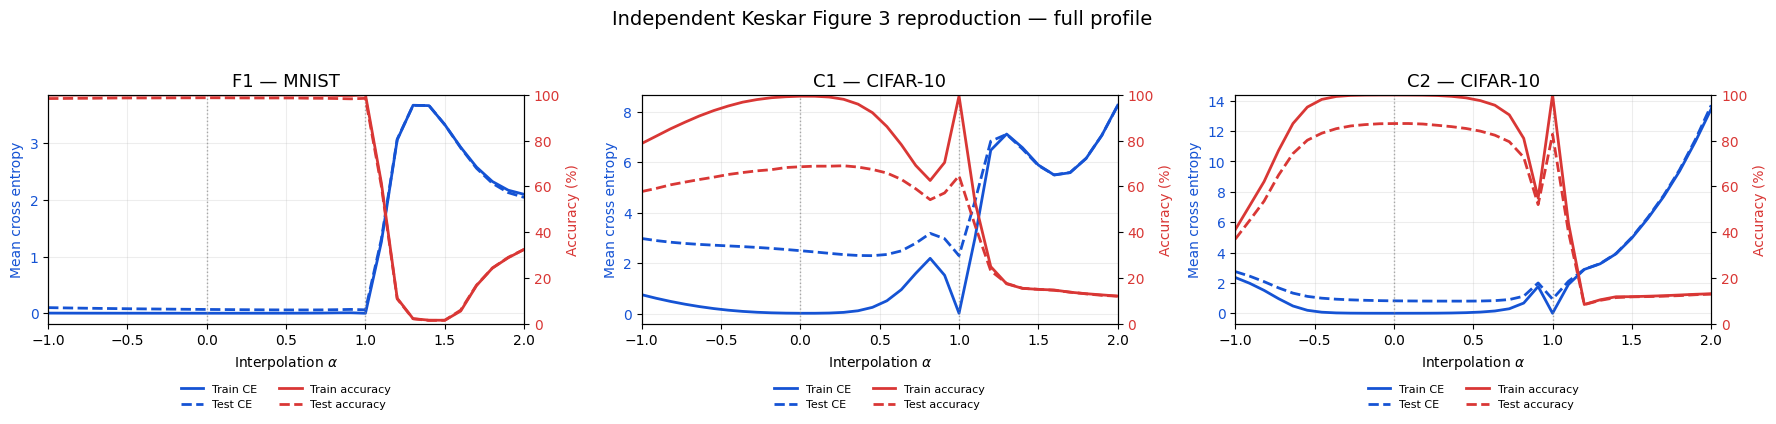

In [6]:
def load_landscape_results(panel):
    # Directory and naming are determined by worker fingerprints; one result per panel/seed.
    latest=ROOT/'landscapes'/f'{panel}_latest.json'
    if not latest.exists():
        raise RuntimeError(f'No completed landscape manifest for {panel}: {latest}')
    files=[Path(json.loads(latest.read_text())['path'])]
    if not files[0].exists():raise FileNotFoundError(files[0])
    data=json.loads(files[0].read_text())
    rows=sorted(data['results'].values(),key=lambda r:r['alpha'])
    if len(rows)!=len(data['metadata']['alpha_grid']):
        raise RuntimeError(f'{panel} curve incomplete ({len(rows)} points)')
    return rows,files[0]

LANDSCAPES={p:load_landscape_results(p) for p in RUN_PANELS}
def save_plot(all_results,filename='Keskar_Figure3_Reproduced'):
    panels=[p for p in ['F1','C1','C2'] if p in all_results]
    assert panels, 'No experiment results found'
    fig,axes=plt.subplots(1,len(panels),figsize=(6.0*len(panels),4.7),squeeze=False,sharex=True)
    for ax,p in zip(axes[0],panels):
        rows=all_results[p][0]
        x=np.asarray([r['alpha'] for r in rows]);
        loss_train=np.asarray([r['train_ce'] for r in rows]);
        loss_test=np.asarray([r['test_ce'] for r in rows]);
        acc_train=np.asarray([r['train_acc'] for r in rows]);
        acc_test=np.asarray([r['test_acc'] for r in rows]);
        b1=ax.plot(x,loss_train,color='#1553D4',lw=2.0,ls='-',label='Train CE')[0]
        b2=ax.plot(x,loss_test,color='#1553D4',lw=2.0,ls='--',label='Test CE')[0]
        ax.set_xlim(-1,2); ax.set_xlabel(r'Interpolation $\alpha$')
        ax.set_ylabel('Mean cross entropy',color='#1553D4')
        ax.tick_params(axis='y',labelcolor='#1553D4')
        ax.grid(True,alpha=.22)
        for endpoint in [0,1]: ax.axvline(endpoint,color='gray',ls=':',lw=1,alpha=.65)
        ax2=ax.twinx()
        r1=ax2.plot(x,acc_train,color='#D93735',lw=2,ls='-',label='Train accuracy')[0]
        r2=ax2.plot(x,acc_test,color='#D93735',lw=2,ls='--',label='Test accuracy')[0]
        ax2.set_ylim(0,100); ax2.set_ylabel('Accuracy (%)',color='#D93735')
        ax2.tick_params(axis='y',labelcolor='#D93735')
        ax.set_title(f'{p} — {"MNIST" if p=="F1" else "CIFAR-10"}',fontsize=13)
        ax.legend([b1,b2,r1,r2],[i.get_label() for i in [b1,b2,r1,r2]],
                  loc='upper center',bbox_to_anchor=(.5,-.22),ncol=2,fontsize=8,frameon=False)
    fig.suptitle(f'Independent Keskar Figure 3 reproduction — {PROFILE} profile',fontsize=14)
    fig.tight_layout(rect=[0,.025,1,.95])
    out_dir=ROOT/'figures';out_dir.mkdir(parents=True,exist_ok=True)
    for ext in ['png','pdf','svg']:
        dest=out_dir/(filename+'_'+PROFILE+'.'+ext)
        fig.savefig(dest,dpi=230,bbox_inches='tight')
        print('Saved',dest)
    plt.show()


save_plot(LANDSCAPES,filename='Keskar_Figure3_Kaggle_2xT4')

## 7. Endpoint checks against paper Table 2

These diagnostics read the **actual full-dataset trained-model evaluations** after BN recalibration. The paper target numbers are five-trial averages; this notebook has only one SB/LB trial per panel, so individual results need not match exactly. The notebook logs any remaining discrepancies or OOM failures in `worker_logs/` and `EVENTS.jsonl`.

In [7]:
PAPER_TARGETS = {
 'F1':{'train_SB':99.66,'train_LB':99.92,'test_SB':98.03,'test_LB':97.81},
 'C1':{'train_SB':99.89,'train_LB':99.66,'test_SB':80.04,'test_LB':77.26},
 'C2':{'train_SB':99.99,'train_LB':99.99,'test_SB':89.24,'test_LB':87.26},
}

def report_diagnostics(all_results):
    for p,(rows,path) in all_results.items():
        by_alpha={round(r['alpha'],8):r for r in rows}
        assert 0.0 in by_alpha and 1.0 in by_alpha, 'Missing exactly calibrated SB/LB endpoint'
        sb,lb=by_alpha[0.0],by_alpha[1.0]
        target=PAPER_TARGETS[p]
        print(f'\n{p}  (observed endpoints with recalibrated BN; paper Table 2 targets are 5-run means)')
        for regime,row in [('SB',sb),('LB',lb)]:
            print(f' {regime}: train={row["train_acc"]:6.2f}% (paper {target["train_"+regime]:5.2f}%), '
                  f'test={row["test_acc"]:6.2f}% (paper {target["test_"+regime]:5.2f}%), '
                  f'train CE={row["train_ce"]:.4f}, test CE={row["test_ce"]:.4f}')
        for r in rows:
            assert r['bn_calibration_n']>0
            for k in ['train_ce','test_ce','train_acc','test_acc']:
                assert np.isfinite(r[k]),(p,r['alpha'],k)
            assert 0<=r['train_acc']<=100 and 0<=r['test_acc']<=100
        assert np.all(np.diff([r['alpha'] for r in rows])>0)
        print(' Cache:',path)
report_diagnostics(LANDSCAPES)


F1  (observed endpoints with recalibrated BN; paper Table 2 targets are 5-run means)
 SB: train= 99.97% (paper 99.66%), test= 98.73% (paper 98.03%), train CE=0.0010, test CE=0.0677
 LB: train=100.00% (paper 99.92%), test= 98.48% (paper 97.81%), train CE=0.0003, test CE=0.0608
 Cache: /kaggle/working/Keskar_Figure3_Independent/landscapes/F1_full_seed2026_52d04786_6a88193b.json

C1  (observed endpoints with recalibrated BN; paper Table 2 targets are 5-run means)
 SB: train= 99.42% (paper 99.89%), test= 68.58% (paper 80.04%), train CE=0.0191, test CE=2.4965
 LB: train= 99.53% (paper 99.66%), test= 64.63% (paper 77.26%), train CE=0.0196, test CE=2.2993
 Cache: /kaggle/working/Keskar_Figure3_Independent/landscapes/C1_full_seed2026_6dc728e2_4a7f3028.json

C2  (observed endpoints with recalibrated BN; paper Table 2 targets are 5-run means)
 SB: train= 99.95% (paper 99.99%), test= 87.46% (paper 89.24%), train CE=0.0016, test CE=0.8189
 LB: train= 99.98% (paper 99.99%), test= 82.78% (paper 87.

## 8. Kaggle persistence and submission

After **Run All** completes, choose **Save Version** to preserve `/kaggle/working` outputs. Output directory includes `run_config.json`, `EVENTS.jsonl`, `checkpoints/` (`last.pt`, `best.pt`, optimizer/RNG state and history), `landscapes/` (per-α JSON/CSV and BN endpoint comparisons), `figures/` (PNG/PDF/SVG) and `worker_logs/`.

To resume in a *different* Kaggle session, attach the prior saved Kaggle outputs as a dataset, set `PREVIOUS_RUN` near the beginning to that read-only input folder, and run all cells. Checkpoint resume checks the experimental identity. **Kaggle Save Version must retain the output**; there is no Google Drive auto-save in Kaggle.

Reproduction limitations to disclose in the report: undisclosed original optimizer/architecture settings filled by explicit assumptions; virtual-batch gradient accumulation is **not** physical large-batch BN; shared initialization is our deliberate control; BN is recalibrated rather than interpolated as a buffer; finite epoch caps and plateau stopping; one trial rather than five. The raw train/test accuracy curves use all samples, but small deviations from paper plots are possible. Document actual failures and corrections from worker logs and event files.